In [1]:
# pip install stackstac

  Using cached stackstac-0.5.1-py3-none-any.whl.metadata (8.1 kB)
Using cached stackstac-0.5.1-py3-none-any.whl (64 kB)
Note: you may need to restart the kernel to use updated packages.


## GEOM7001 Project - Study Site Plotting
This notebook plots the study site for the GEOM7001 project, including the pologons of the paddocks as supplied by the Lower Clarence Harvesting Cooperative. 

### Load packages
The first step is to run `%matplotlib inline`, which ensures figures plot correctly in the Jupyter notebook.
Next, load the `datacube` package to enable loading data, and a selection of custom DEA functions from the [dea_tools.plotting](../Tools/dea_tools/plotting.py) module.

In [2]:
%matplotlib inline

import datacube
import sys
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
import numpy as np

sys.path.insert(1, '../Tools/')
from dea_tools.datahandling import load_ard
from dea_tools.plotting import display_map, rgb

import ipyleaflet
import pystac
import requests
import rich.table
import pystac_client
import planetary_computer
import odc.stac
from odc.geo.geom import BoundingBox
import xarray as xr

import pyogrio


from IPython.display import Image

### Connect to the datacube
The next step is to connect to the datacube database.
The resulting `dc` datacube object can then be used to load data.
The `app` parameter is a unique name used to identify the notebook that does not have any effect on the analysis.

In [3]:
dc = datacube.Datacube(app="05_Plotting")

### Study Site Bounding Box and Date to Plot
Plotting for 2018 as that is the year the shape files were supplied for. 

In [4]:
lat_range = (-29.4336, -29.4841)
lon_range = (153.2438, 153.2906)
time_range = ("2018-04-01", "2018-05-31")

## View the queried location
Before running a query and extracting and analysing data, it is useful to double-check that your location is correct.
The `display_map()` function shows your selected area as a red rectangle on an interactive map.
Clicking on any point of the map will reveal the latitude and longitude coordinates of that point.

In [5]:
display_map(x=lon_range, y=lat_range)

## Load Sentinel-2 Data
The variables specified above are used to load data from  the DEA datacube through the `dc.load()`.

### Load Shapefile Polygons

The shapefiles provided cover the whole Harwoord growing region, and we will need to clip this to cover just our study site in Palmers Channel and Palmers Island.

In [6]:
shp = gpd.read_file("EXP_PAD_CUR_2018_region.shp")

# Convert shapefile to WGS84
shp_wgs84 = shp.to_crs("EPSG:4326")

#Study area bounding box
bbox = box(
    lon_range[0],
    lat_range[0],
    lon_range[1],
    lat_range[1]
)

# Only polygons that are completely within the study area are kept
shp_inBB = shp_wgs84[
    shp_wgs84.geometry.within(bbox)
].copy()

print("Original polygons:", len(shp_wgs84))
print("Polygons completely inside:", len(shp_inBB))



Original polygons: 5202
Polygons completely inside: 598


### Keep only polygons with dimensions greater than 30m x 30m 
Must be no less than 3 Sentinel-2 pixels wide

In [7]:
def get_dimensions(polygon):
    rect = polygon.minimum_rotated_rectangle
    coords = list(rect.exterior.coords)

    lengths = []

    for i in range(4):
        x1, y1 = coords[i]
        x2, y2 = coords[i + 1]
        length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        lengths.append(length)

    lengths.sort()

    return lengths[0], lengths[2]

shp_3577 = shp_inBB.to_crs("EPSG:3577")

dimensions = shp_3577.geometry.apply(get_dimensions)

shp_3577["min_width_m"] = dimensions.apply(lambda x: x[0])
shp_3577["min_length_m"] = dimensions.apply(lambda x: x[1])

dimension_mask = (
    (shp_3577["min_width_m"] > 30) &
    (shp_3577["min_length_m"] > 30)
)

shp_filtered = shp_3577[dimension_mask].copy()

shp_filtered.to_file('study-site-polygons.shp') #export as shapefile to use in other notebooks

print("Polygons > 30 m × 30 m:", len(shp_filtered))

Polygons > 30 m × 30 m: 491


/tmp/ipykernel_216/2223368132.py:31: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  shp_filtered.to_file('study-site-polygons.shp') #export as shapefile to use in other notebooks
/env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Field START create as date field, though DateTime requested.
  ogr_write(
/env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Field END create as date field, though DateTime requested.
  ogr_write(
/env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Field PLANTED create as date field, though DateTime requested.
  ogr_write(
/env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'min_width_m' to 'min_width_'
  ogr_write(
/env/lib/python3.10/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'min_length_m' to 'min_length'
  ogr_write(


### Calculate some statistics for the polygons

In [8]:
import numpy as np

average_area = shp_filtered.area.mean()
min_area = shp_filtered.area.min()
max_area = shp_filtered.area.max()
total_area = shp_filtered.area.sum()


print(f"Average polygon area: {average_area:.2f} m²")
print(f"Minumum polygon area: {min_area:.2f} m²")
print(f"Maximum polygon area: {max_area:.2f} m²")
print(f"Total polygon area: {total_area:.2f} m²")

print(f"Minimum width:  {shp_filtered['min_width_m'].min():.2f} m")
print(f"Minimum length: {shp_filtered['min_length_m'].min():.2f} m")



Average polygon area: 19274.15 m²
Minumum polygon area: 1377.69 m²
Maximum polygon area: 89833.77 m²
Total polygon area: 9463606.44 m²
Minimum width:  30.09 m
Minimum length: 48.20 m


## Plot 
The True Colour Sentinel-2 image is plotted with the polygons overlayed

Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 3 out of 12 time steps with at least 99.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Returning 3 time steps as a dask array


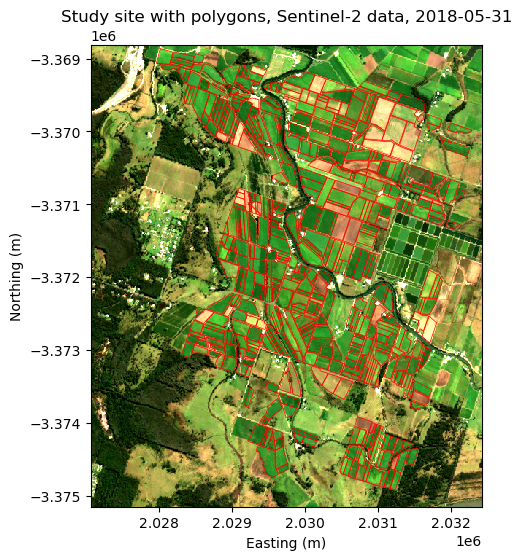

In [21]:


# plot Sentinel-2 data
query = {
    "x": lon_range,
    "y": lat_range,
    "time": time_range,
    "resolution": (-10, 10),
    "output_crs": "EPSG:3577",
    "group_by": "solar_day"
    }


ds = load_ard(
    dc=dc,
    products=[
        'ga_s2am_ard_3',
        'ga_s2bm_ard_3',
        'ga_s2cm_ard_3'
    ],
    cloud_mask='s2cloudless',
    min_gooddata=0.99,
    dask_chunks={'time': 1},
    **query,
)

ds = ds.isel(time=len(ds.time)-1) #plot the last timestep before harvest season
date = ds.time.dt.strftime('%Y-%m-%d').item()

rgb(
    ds,
    bands=['nbart_red', 'nbart_green', 'nbart_blue']
)

ax = plt.gca()


# Convert the selected polygons to the same CRS used by the Sentinel-2 data loaded
shp_plot = shp_filtered.to_crs(ds.odc.geobox.crs)

# Overlay polygons
shp_plot.plot(
    ax=ax,
    facecolor='none',
    edgecolor='red',
    linewidth=0.5,
    aspect='equal'
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

plt.savefig('Results/study-site-plot.png')

plt.title("Study site with polygons, Sentinel-2 data, " + date)
plt.show()

### Plot just 130 McLeays Lane
The farm where field data is available

In [22]:
lat_range_130McLn = (-29.4739, -29.4841)
lon_range_130McLn = (153.2782, 153.2906)
time_range_130McLn = ("2024-06-01", "2024-08-01")


In [33]:
query = {
    "x": lon_range_130McLn,
    "y": lat_range_130McLn,
    "time": time_range_130McLn,
    "resolution": (-10, 10),
    "output_crs": "EPSG:3577",
    "group_by": "solar_day"
    }


ds_130McLn = load_ard(
    dc=dc,
    products=[
        'ga_s2am_ard_3',
        'ga_s2bm_ard_3',
        'ga_s2cm_ard_3'
    ],
    cloud_mask='s2cloudless',
    min_gooddata=0.99,
    dask_chunks={'time': 1},
    **query,
)

ds_130McLn = ds_130McLn.isel(time=0) #pick the first one


Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 7 out of 12 time steps with at least 99.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Returning 7 time steps as a dask array


In [34]:
#130 McLeays Lane Palmers Channel
bbox_130McLn = box(
    lon_range_130McLn[0],
    lat_range_130McLn[0],
    lon_range_130McLn[1],
    lat_range_130McLn[1]
)

shp_wgs84 = shp_filtered.to_crs("EPSG:4326")

shp_130McLn = shp_wgs84[
    shp_wgs84.geometry.within(bbox_130McLn)
].copy()

print("Num polygons @ 130 McLeays Lane:", len(shp_130McLn))

Num polygons @ 130 McLeays Lane: 32


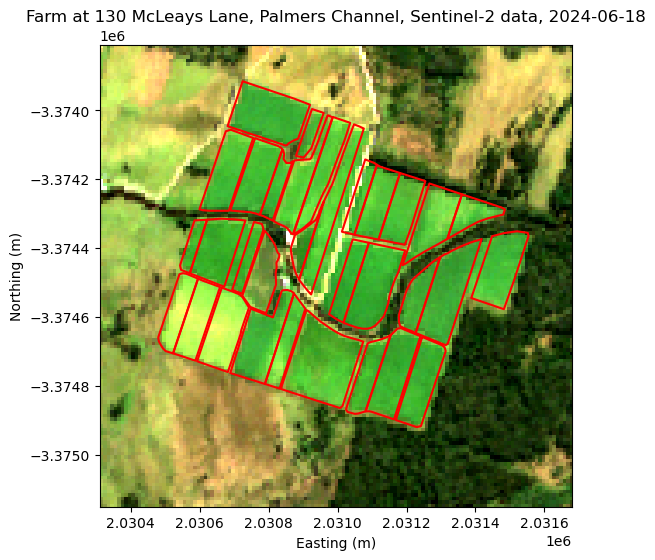

In [35]:
date = ds_130McLn.time.dt.strftime('%Y-%m-%d').item()

rgb(
    ds_130McLn,
    bands=['nbart_red', 'nbart_green', 'nbart_blue']
)

ax = plt.gca()


# Convert the selected polygons to the same CRS used by the Sentinel-2 data loaded
shp_plot = shp_130McLn.to_crs(ds_130McLn.odc.geobox.crs)

# Overlay polygons
shp_plot.plot(
    ax=ax,
    facecolor='none',
    edgecolor='red',
    linewidth=1.5,
    aspect='equal'
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

plt.savefig('Results/training-site-plot.png')

plt.title("Farm at 130 McLeays Lane, Palmers Channel, Sentinel-2 data, " + date)
plt.show()